# Генераторы

Материалы из `04_classes_basics.ipynb`: итераторы, ленивые вычисления, `zip` и примеры генераторных функций с `yield from`.


In [ ]:
import random


## Как в питоне работают итераторы

Что вообще такое итератор?

Начнем с обычного списка

In [144]:
numbers = [10, 20, 30]

for i in numbers:
    print(i)

10
20
30


Мы знаем, что цикла последовательно получает элементы цикла, но как питон понимает, какой элемент отдать следующим? 

Здесь и вступаю в роль итератор и его мето

- `__iter__()` - позволяет получить итератор объекта
- `__next__()` - возвращает следующий элемент или сообщает, что элементы закончились

#### Разница между итератором и итерируемым объектом

Итерируемый объект - объект, от которого можно получить итератор через `iter()`

Итератор - объект, который умеет последовательно выдавать значения через`next()` и сообщать об окончании перебора

In [145]:
numbers = [10, 20, 30]

In [147]:
iterator = iter(numbers)
iterator

In [148]:
iterator.__next__()

10

In [149]:
iterator.__next__()

20

Напишем класс, который будет уметь подбрасывать монетку и останавливаться, когда выпадет `side`

In [ ]:
class CoinFlip:
    SIDE = ['head', 'tails']

    def __init__(self, side: str):
        self.side = side

    # разобрано ниже
    def __iter__(self):
        return self

    def __next__(self):
        side = CoinFlip.SIDE[random.randint(0, 1)]

        if side == self.side:
            raise StopIteration

        return side

Вот этот метод

```
def __iter__(self):
    return self
```

Возвращает сам объект `self`, то есть говорит экземляру чтобы он возврашал сам себя в качестве итератора


В качестве метода `__next__` в классе выше определен метод со своей логикой

In [137]:
for i in CoinFlip('head'):
    print(i)

tails


In [141]:
coin = CoinFlip('head')

In [142]:
for i in coin:
    print(i)

tails


На самом деле как работает цикл for - это просто while по итерируемому объекту, который сам же его и создает и который сам потом вызывает метод `__next__` пока не вернется `StopIteration`

In [150]:
iterator = iter(CoinFlip('head'))

while True:
    try:
        i = next(iterator)
    except StopIteration:
        break

    print(i)

tails


#### Зачем вообще создавать свои итераторы? - lazy evaluation

Потому что не всегда нужно хранить все значения в списке, а лишь получать их по мере необходимости

это назвается `lazy evaluation` - значения создаются по запросу, а не все сразу

Напишем итератор который выдает числа до заданного значения, и не хранит их предварительно в памяти

In [11]:
class Counter:
    def __init__(self, limit):
        self.limit = limit
        self.current = 0

    # здесь Counter одновременно и итерируемый объект и итератора
    # это нужно чтобы можно было оборачивать итераторы в итераторы и у нас все равно сохранялась позиция на которой мы итерируемся
    def __iter__(self):
        return self

    def __next__(self):
        if self.current >= self.limit:
            raise StopIteration

        self.current += 1
        return self.current

# создавать iter() не надо так как for сам это делает под капотом
count = Counter(5)

for el in count:
    print(el)
    

1
2
3
4
5


In [13]:
count = Counter(5)
print(list(count))
print(list(count))

[1, 2, 3, 4, 5]
[]


In [163]:
for el in count:
    print(el)

Ничего нет, потому что итератор уже выдал все свои значения

Это особенность реализации класса `Counter`, тут итератор и итерируемый объект это и есть класс Counter из-за `__init__`

А вот класс ниже реализует отдельный итератор на каждый итерируемый объект

```
def __iter__(self):
    return MyListIterable.MyListIterator(self.values)
```

Рассмотрим пример класса с разделением на итератор и итерируемый объект

Класс хранит список значений и умеет создавать новые

Чтобы миновать проблему, когда итератор исчерпывает элементы и при выхове повторном он не отдает список снова, надо разделить итератор и итерируемый объект

Тут надо помнить, что `__iter__()` - это магический метод и соответственно его можно переопределить

In [25]:
class Counter:
    def __init__(self, limit):
        self.limit = limit

    def __iter__(self):
        print('Создан новый итератор')
        return CounterIterator(self.limit)

class CounterIterator:
    def __init__(self, limit):
        self.limit = limit
        self.count = 0

    def __iter__(self):
        return self

    def __next__(self):
        if self.count >= self.limit:
            raise StopIteration

        self.count += 1
        return self.count


it1 = Counter(5)
print(list(it1))
print(list(it1))
print(list(it1))

Создан новый итератор
[1, 2, 3, 4, 5]
Создан новый итератор
[1, 2, 3, 4, 5]
Создан новый итератор
[1, 2, 3, 4, 5]


Это так работает потому что:
- it1 = Counter(5) создает просто Counter и вызывает только `__init__`
- далее list неявно вызывает метод `iter()` а тот в своб очередь вызывает метод `__iter__()` внутренний

Получается на каждый вызов мы создаем новый CounterIterator вот и все

Но если сделать так

In [ ]:
it1 = Counter(5)
iterator = iter(it1)

print(list(iterator))
print(list(iterator))

Создан новый итератор
[1, 2, 3, 4, 5]
[]


тут наш внутренний метод `__iter__` вызывад метод `iter()` и поэтому в дальнейшем ссылка вернется на созданный объект

### Примеры с итераторами

Тут видно, как ссылки на итерируемый объект 

In [1]:
numbers = [10, 20, 30]

a = iter(numbers)
b = iter(numbers)
c = a

print(next(a))
print(next(b))
print(next(c))
print(next(a))

10
10
20
30


1) Что такое итерируемый объект? - это объект из которого можно получить итератор с помощью iter() (list, tuple, str, dict)

2) Итератор - это объект, который выдает элементы по одному при вызове специального метода next() и хранит состояние обхода

Итератор реализует два метода - `__iter__()`, `__next__()`

3) Почему при повторном обходе списка через for мы снова получаем все объекты, а через один и тот же итератор - нет?

Потом что итератор хранит собственное состояние итерации, поэтому при повторном обращении к итератору мы продолжим обход с последней сохраненной позиции

4) Можно ли считать любой итератор итерируемым объектом? А любой итерируемый объект — итератором?

любой итератор итерируемым объектом - да, потому что итератор реализует мтеод `__iter__()` который возвращает сам объект, то есть итератор тоже можно передать в цикл for. Или - итератор реализует протокол `__iter__()` поэтому тоже являетяс итерируемым объектом

но не каждый итерируемый объект является итератором, на просто список нельзя вызывать метод `__next()__`

то есть итератор является подмнгожеством итерируемых объектов

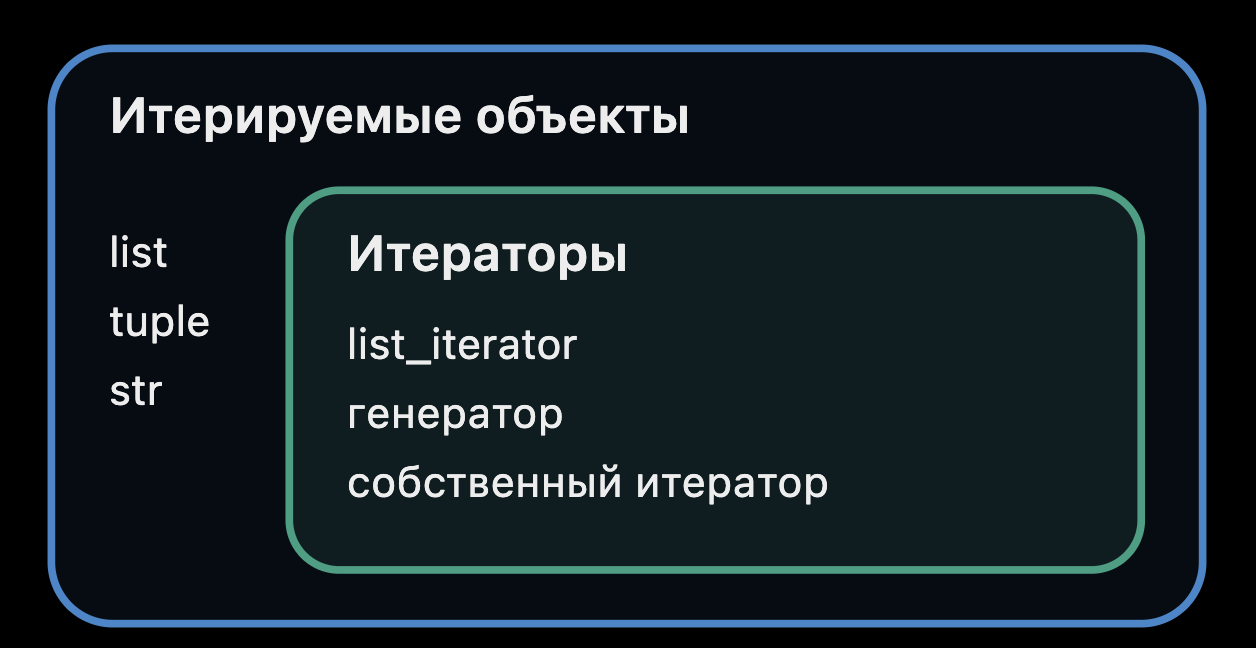


5) Зачем итератору вообще нужен метод __iter__(), который возвращает самого себя, если для получения элементов у него уже есть __next__()?

Метод `__iter()__` возвращает ссылку на сам итератор

In [5]:
obj = (1, 2, 3)

for x in obj:
    print(x)

1
2
3


Под капотом там происходит примерно следующее

In [6]:
iterator = iter(obj)

while True:
    try:
        x = iterator.__next__()
    except StopIteration:
        break

    print(x)

1
2
3


In [7]:
iterator = iter(obj)

for x in iterator:
    print(x)

1
2
3


In [8]:
for x in obj:
    print(x)

1
2
3


Циклу for пофигу, объект уже итератор или еще нет

ПОчему так? Потому что метод `__iter__()` возвращает ссылку на самого себя и даже если итератор снова обернуть в итератор он все равно вернет себя, то есть итераторы можно сколко угодно оборачивать друг в друга, смысл от этого не изменится

Еще пример на это

In [ ]:
numbers = [1, 2, 3]
it = iter(numbers)

next(it)

for x in iter(it): # хоть мы и обернули тут все равно вернулся старый итератор
    print(x)

2
3


In [ ]:
class MyIterator:
    def __iter__(self):
        return self

In [159]:
# итерируемый объект - как получить итератор?
class MyListIterable:

    # итератор - как получить следующий элемент
    class MyListIterator:
        def __init__(self, values):
            self.values = values
            self.index = 0

        def __iter__(self):
            return self

        def __next__(self):
            if self.index >= len(self.values):
                raise StopIteration

            value = self.values[self.index]
            self.index += 1

            return value

    def __init__(self, values):
        self.values = values

    def __iter__(self):
        return MyListIterable.MyListIterator(self.values)

In [160]:
iterator = MyListIterable([1, 2, 3])

In [161]:
numbers = MyListIterable([10, 20, 30])

for number in numbers:
    print(number)

10
20
30


In [162]:
for number in numbers:
    print(number)

10
20
30


То есть итерируемый объект говорит нам о том, как полуичть итератор и реализует метод `__iter__()`

А итератор говорит о том, как получить следующий объект в итераторе и реализует методы `__iter__()` и `__next()__`

Подытожим

Итерируемые обьекты - это те, которые можно перебрать, например списки и строки (а ещё кортежи, множества, словари и.т.п).

Итератор - это обьект, который возвращает свои элементы по одному за раз. Когда элементы заканчиваються, итератор возвращает исключение StopIteration.

- Элементы итератора можно перебрать всего один раз, для последующих придется заново создавать итератор.
- Доступ к обьекту по итератору и по индеку - не одно и тоже.
- Итераторы используються если нужно постоянно перебирать итерируемые обьекты разных типов (например, это происходит в цикле for).

Важно понимать, что при вызове на уже пройденном списке метода `__next()__` итератор вернет исключение (именно исключение это важно) `StopIteration`

## Метод Zip

Объединяет несколько итерируемых объекта попарно

Возвращает объект итератор, по которому можно итерироваться, то есть он делает ленивое вычисление

zip возвращает и итератор и итерируемый объект

Работет лениво

In [204]:
names = ['Masha', 'Tanya', 'Alina']
ages = [22, 23, 24]

iterator = zip(names, ages)

In [205]:
iterator.__next__()

('Masha', 22)

Решим задачку на поворот матрицы

Это можно легко сделать с помощью zip

Правда zip можно сказать вертит матрицу против часовой стрелки, поэтому нам нужно еще и вернуть массив в обратном порядке

In [198]:
matrix = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9],
    [1, 2, 3]
]

k = 2

it = zip(*matrix)

del matrix

matrix = []

for el, i in enumerate(it):
   matrix.append([*i[::-1]])

print(matrix)
print('\n')

it = zip(*matrix)

del matrix

matrix = []

for el, i in enumerate(it):
   matrix.append([*i[::-1]])

print(matrix)
print('\n')

it = zip(*matrix)

del matrix

matrix = []

for el, i in enumerate(it):
   matrix.append([*i[::-1]])

print(matrix)
print('\n')

it = zip(*matrix)

del matrix

matrix = []

for el, i in enumerate(it):
   matrix.append([*i[::-1]])

print(matrix)
print('\n')

[[1, 7, 4, 1], [2, 8, 5, 2], [3, 9, 6, 3]]


[[3, 2, 1], [9, 8, 7], [6, 5, 4], [3, 2, 1]]


[[3, 6, 9, 3], [2, 5, 8, 2], [1, 4, 7, 1]]


[[1, 2, 3], [4, 5, 6], [7, 8, 9], [1, 2, 3]]




Запишем эту задачу в нормальном виде, чтобы повернуть матрицу k раз

In [218]:
k = 3

matrix = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9],
    [1, 2, 3]
]

for i in range(k):
    iterator = zip(*matrix)

    del matrix
    matrix = []

    for i, el in enumerate(iterator):
        matrix.append([*el[::-1]])

print(matrix)

[[3, 6, 9, 3], [2, 5, 8, 2], [1, 4, 7, 1]]


## Вспомогательные классы для практики

Определения из исходного ноутбука, необходимые для примеров с `Office` ниже.


In [1]:
from abc import ABC, abstractmethod

In [14]:
import random

class Room(ABC):

    def __init__(self, number: int, building: str, capacity: int):
        self.number = number
        self.building = building
        self.capacity = capacity
        self.is_occupid = False

    def str(self) -> str:
        return f'{self.building}{self.number}'

    def occupy(self):
        assert not self.is__occupied, 'ЗАНЯТО GO AWAY'

    def free(self):
        assert self.is_occupid, 'DOUBLE FREE OR CORRUPTION'

    # в питоне нет проверки реализации методов и на этапе написания кода, мы не можем понять, реализован ли родительский метод ребенком

    # чтобы это как-то косо обойти, можно прописывать методы с raise NotImplementedError, чтобы при вызове метода через ребенка мы понимали, что забыла реализовать его. Но это сработает только в момент вызова

    def look(self):
        raise NotImplementedError

    @abstractmethod
    def sing(self):
        print('singing')

In [29]:
# наследование
class Office(Room):
    def __init__(self, number: int, building: str, capacity: int, *employees: str):
        super().__init__(number, building, capacity)
        self.employees = list(employees)

        assert len(self.employees) <= capacity

    def fire(self, employees: str):
        self.employees.remove(employees)

    def sing(self):
        print('Реализация абстрактного метода') 


    def __str__(self):
        return f'{super().__str__()}({" ".join(self.employees)})'
    

Практика

In [ ]:
# декоратор функции класса для абстрактных методов которые не реализованы
# декоратор который проверяет что все методы реализованы

# getattr(method, ) - пытается получить метод поля с такми классом
from collections.abc import Callable

def get_not_implemented_methods(cls):
    # собарть все множества чтобы найти методы которые мы еще не реализовали

    not_implemented = set()

    for base in cls.__bases__:
        not_implemented |= get_not_implemented_methods(base)

    callable_methods = {
            name 
            for (name, method) in cls.__dict__.items() 
            if isinstance(name, Callable) and not getattr(method, "__not_implemented_to", False)
        }

    not_implemented -= callable_methods

    # надо добавить наши имплементированные методы
    not_implemented |= {
        name 
        for (name, method) in cls.__dict__.items() 
        if getattr(method, "__not_implemented_to", False)

    }

    return not_implemented

def not_implemented_methods(cls):
    yield from (name for (name, method) in cls.__dict__.items() if getattr(method, "__not_implemented_to", False))

    for base in cls.__bases__:
        # все неиплементированные методы родителя
        yield from not_implemented_methods(base)

def get_callable_methods(cls):
    yield from (name for (name, method) in cls.__dict__.items() if not getattr(method, "__not_implemented_to", False))

    for base in cls.__bases__:
        # все неиплементированные методы родителя
        yield from get_not_implemented_methods(base)


def not_implemented(f: Callable):
    f.__not_implemented_to = True

    return f

def check_implemented(cls: type):
    
    assert not get_not_implemented_methods(cls)

    pass

In [ ]:
isinstance(Office.__dict__['fire'], Callable)

True

In [ ]:
Office.__dict__

mappingproxy({'__module__': '__main__',
              '__init__': <function __main__.Office.__init__(self, number: int, building: str, capacity: int, *employees: str)>,
              'fire': <function __main__.Office.fire(self, employees: str)>,
              '__doc__': None})

In [ ]:
Office.__bases__ # выводит родительский самый верхний класс

(__main__.Room,)

In [ ]:
class Foo:
    def __init__(self):
        pass
    @not_implemented
    def foo():
        pass

class Fizz():
    def foo():
        pass

class Bar(Foo):
    def __init__(self):
        pass
     
    @not_implemented
    def bar(self):
        pass

list(not_implemented_methods(Bar))

['bar', 'foo']

In [ ]:
@check_implemented
class FooBarr(Bar):
    pass

set()


AssertionError: Method bar is not implemented

In [ ]:
@check_implemented
class FooBarr(Bar, Fizz):
    def foo(self):
        pass

set()


AssertionError: Method bar is not implemented

In [ ]:
@check_implemented
class FooBarr(Bar):
    def foo(self):
        pass
    def bar(self):
        pass

set()


AssertionError: Method bar is not implemented